# Entrenamiento y confirmación

Cristhian Pazmino Parra · Universidad Espíritu Santo

Inspecciona las corridas ejecutadas. Reutiliza sus pesos verificados; no simula haber reentrenado al abrir el cuaderno.

Referente: anotaciones publicadas sin adjudicación local. Los datos permanecen fuera del repositorio.

In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd()
assert (ROOT / "src").is_dir(), "Ejecutar desde la raíz del repositorio"
sys.path.insert(0, str(ROOT))
LOCAL = Path.home() / "AppData/Local/DentalAI"
DATA = LOCAL / "data/research_v2"
REPORTS = ROOT / "reports/completion"
def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))
from IPython.display import display, Markdown, Image


In [2]:
from src.data.contract import sha256_file
confirmations = read(REPORTS / "confirmation.json")
assert len(confirmations) == 6
summary = []
for item in confirmations:
    run = Path(item["run"])
    record = read(run / "run.json")
    assert record["status"] == "completed"
    assert sha256_file(run / "weights/best.pt") == record["best_sha256"]
    summary.append({"run": item["name"], "seed": item["seed"], "validation_mAP50": item["validation"]["map50"], "seconds": record["resources"]["train_seconds"], "peak_gpu_GB": record["resources"]["gpu_mem_peak_gb"]})
display(summary)

[{'run': 'baseline_n640_s42',
  'seed': 42,
  'validation_mAP50': 0.6026791256507499,
  'seconds': 937.665,
  'peak_gpu_GB': 2.418},
 {'run': 'selected_n_s42',
  'seed': 42,
  'validation_mAP50': 0.632788968120259,
  'seconds': 1208.075,
  'peak_gpu_GB': 5.849},
 {'run': 'selected_n_s43',
  'seed': 43,
  'validation_mAP50': 0.6292969934809423,
  'seconds': 1269.147,
  'peak_gpu_GB': 5.853},
 {'run': 'selected_n_s44',
  'seed': 44,
  'validation_mAP50': 0.6264831743952752,
  'seconds': 1225.268,
  'peak_gpu_GB': 5.828},
 {'run': 'architecture_26n_s42',
  'seed': 42,
  'validation_mAP50': 0.6204698915097902,
  'seconds': 974.526,
  'peak_gpu_GB': 6.61},
 {'run': 'ablation_mosaic_s42',
  'seed': 42,
  'validation_mAP50': 0.6438972561011195,
  'seconds': 1532.567,
  'peak_gpu_GB': 5.876}]

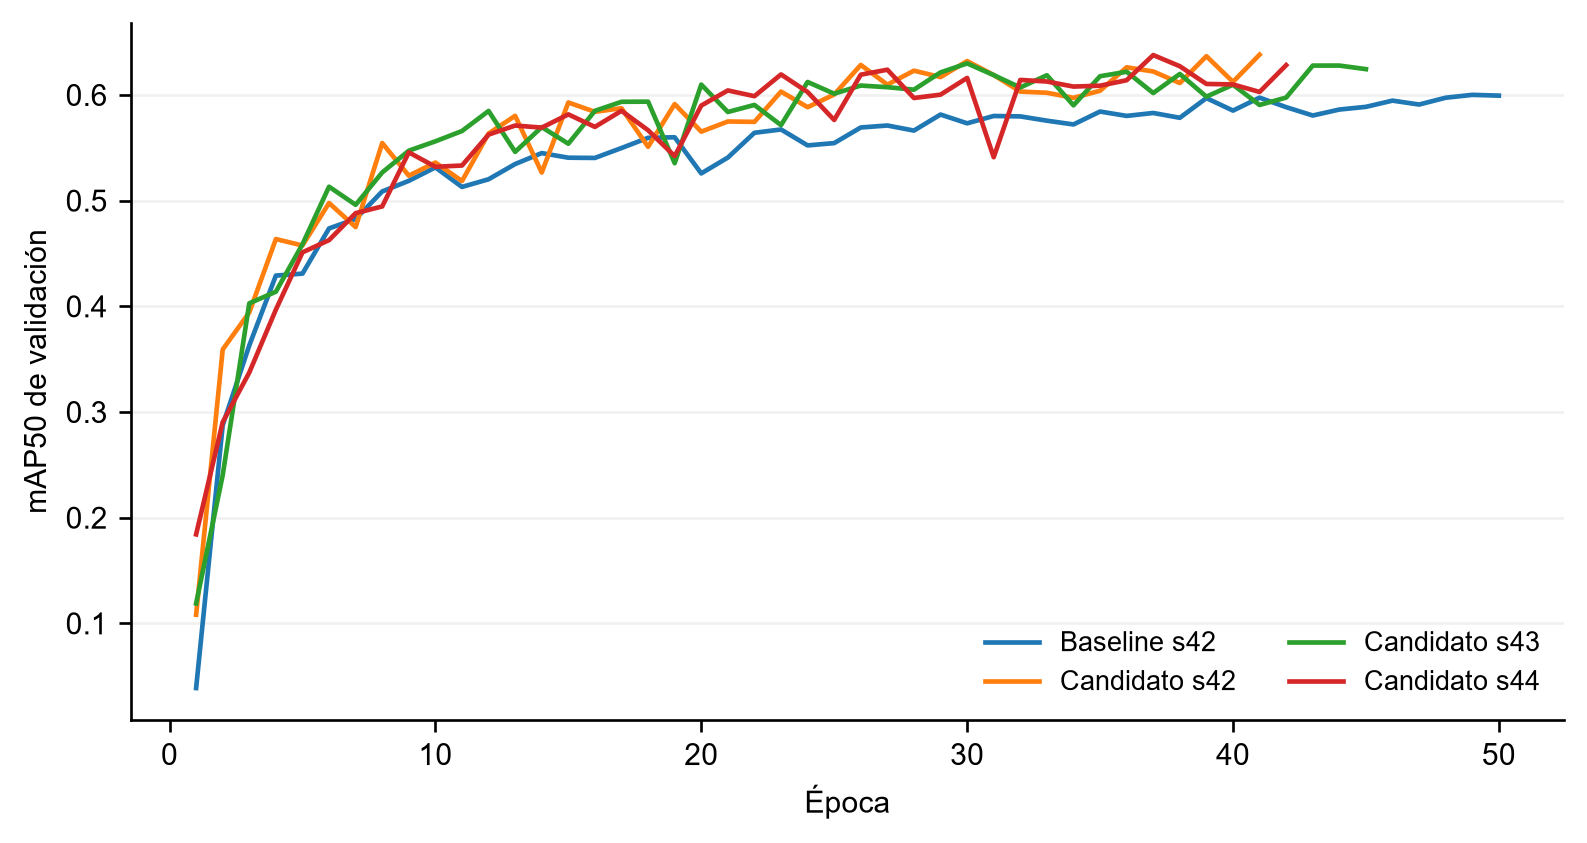

In [3]:
display(Image(filename=str(ROOT / "output/tesis/figures/v2_12_aprendizaje.png")))

Entrenamiento completo reproducible: `.venv-training\Scripts\python.exe scripts/training/complete_research.py experiments`. El protocolo está en `configs/training/research_protocol.yaml`. El runner guarda fallos, configuración efectiva, pesos y recursos. Las comparaciones son de desarrollo; test y externo no se usan para escoger una semilla.